<a href="https://colab.research.google.com/github/Sai-D-beep/Quantum-computing-hackathon/blob/main/Question%20no%2027.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q pennylane networkx scikit-learn matplotlib pandas

In [2]:
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import pennylane as qml
import time
import random

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    confusion_matrix,
    classification_report
)

random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
N_QUBITS = 2
SHOTS = 100
EPOCHS = 20
LEARNING_RATE = 0.02

print("Qubits:", N_QUBITS)
print("Shots:", SHOTS)
print("Epochs:", EPOCHS)
print("Learning rate:", LEARNING_RATE)

Qubits: 2
Shots: 100
Epochs: 20
Learning rate: 0.02


In [4]:
dev = qml.device(
    "default.qubit",
    wires=N_QUBITS,
    shots=SHOTS
)

@qml.qnode(dev, interface="torch", diff_method="parameter-shift")
def quantum_circuit(inputs, weights):

    qml.RY(inputs[0] + weights[0], wires=0)
    qml.RY(inputs[1] + weights[1], wires=1)

    qml.CNOT(wires=[0, 1])

    return qml.expval(qml.PauliZ(0))

weight_shapes = {"weights": (2,)}

quantum_layer = qml.qnn.TorchLayer(
    quantum_circuit,
    weight_shapes
)

print("Quantum circuit created successfully!")

Quantum circuit created successfully!


/usr/local/lib/python3.13/dist-packages/pennylane/devices/device_api.py:207: PennyLaneDeprecationWarning: Setting shots on device is deprecated. Please use the `set_shots` transform on the respective QNode instead.
  warnings.warn(


In [5]:
dummy_input = torch.tensor([0.5, 0.3])
dummy_weights = torch.tensor([0.1, 0.2])

print(
    qml.draw(quantum_circuit)(
        dummy_input,
        dummy_weights
    )
)

0: ──RY(0.60)─╭●─┤  <Z>
1: ──RY(0.50)─╰X─┤     


In [6]:
def extract_features(G):

    degree = dict(G.degree())
    clustering = nx.clustering(G)
    pagerank = nx.pagerank(G)
    core = nx.core_number(G) if G.number_of_edges() else {
        n: 0 for n in G.nodes()
    }

    max_degree = max(degree.values()) or 1
    max_core = max(core.values()) or 1

    features = []

    for node in G.nodes():

        features.append([
            degree[node] / max_degree,
            clustering[node],
            pagerank[node],
            core[node] / max_core
        ])

    return torch.tensor(features, dtype=torch.float32)


def adjacency_matrix(G):

    A = nx.to_numpy_array(G, dtype=np.float32)
    A += np.eye(len(A))

    degree = A.sum(axis=1)
    D = np.diag(1 / np.sqrt(degree))

    return torch.tensor(D @ A @ D, dtype=torch.float32)

Number of nodes: 34
Number of edges: 78


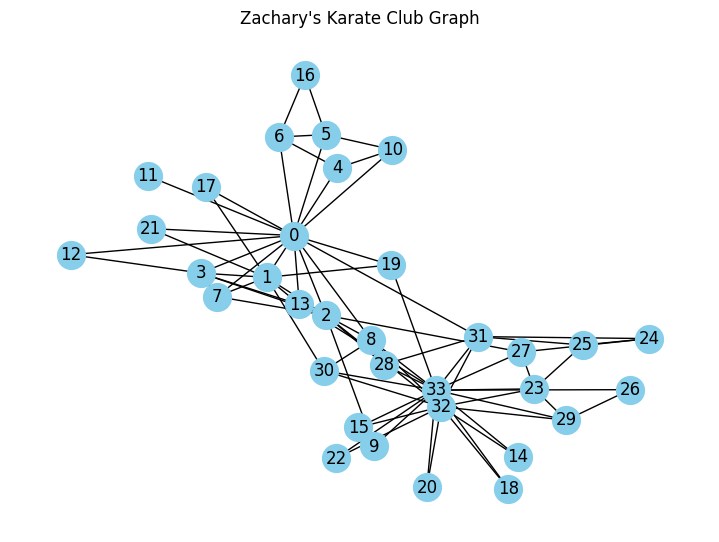

In [7]:
G = nx.karate_club_graph()

print("Number of nodes:", G.number_of_nodes())
print("Number of edges:", G.number_of_edges())

plt.figure(figsize=(7, 5))

pos = nx.spring_layout(G, seed=42)

nx.draw(
    G,
    pos,
    with_labels=True,
    node_color="skyblue",
    node_size=400
)

plt.title("Zachary's Karate Club Graph")
plt.show()

In [8]:
X = extract_features(G)
A = adjacency_matrix(G)

# Club membership is the target only.
y = torch.tensor(
    [
        0 if G.nodes[n]["club"] == "Mr. Hi" else 1
        for n in G.nodes()
    ],
    dtype=torch.long
)

print("Feature shape:", X.shape)
print("Adjacency shape:", A.shape)
print("Target shape:", y.shape)
print("Class counts:", torch.bincount(y))

Feature shape: torch.Size([34, 4])
Adjacency shape: torch.Size([34, 34])
Target shape: torch.Size([34])
Class counts: tensor([17, 17])


In [9]:
indices = np.arange(len(y))

train_idx, test_idx = train_test_split(
    indices,
    test_size=0.30,
    random_state=42,
    stratify=y.numpy()
)

train_idx = torch.tensor(train_idx)
test_idx = torch.tensor(test_idx)

print("Training nodes:", len(train_idx))
print("Testing nodes:", len(test_idx))

Training nodes: 23
Testing nodes: 11


In [10]:
class HybridGNN(nn.Module):

    def __init__(self):

        super().__init__()

        self.linear1 = nn.Linear(4, 8)
        self.linear2 = nn.Linear(4, 8)

        self.quantum = qml.qnn.TorchLayer(
            quantum_circuit,
            {"weights": (2,)}
        )

        self.classifier = nn.Linear(9, 2)

    def classical_gnn(self, X, A):

        neighbor = A @ X

        h = torch.tanh(
            self.linear1(X) +
            self.linear2(neighbor)
        )

        return h

    def quantum_features(self, h):

        q_input = torch.tanh(h[:, :2]) * np.pi

        q_output = torch.stack([
            self.quantum(row)
            for row in q_input
        ])

        return q_output.reshape(-1, 1)

    def forward(self, X, A):

        h = self.classical_gnn(X, A)

        q = self.quantum_features(h)

        combined = torch.cat([h, q], dim=1)

        return self.classifier(combined)


model = HybridGNN()

print(model)

HybridGNN(
  (linear1): Linear(in_features=4, out_features=8, bias=True)
  (linear2): Linear(in_features=4, out_features=8, bias=True)
  (quantum): <Quantum Torch Layer: func=quantum_circuit>
  (classifier): Linear(in_features=9, out_features=2, bias=True)
)


In [11]:
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

loss_function = nn.CrossEntropyLoss()

losses = []

start_time = time.time()

for epoch in range(EPOCHS):

    model.train()

    optimizer.zero_grad()

    output = model(X, A)

    loss = loss_function(
        output[train_idx],
        y[train_idx]
    )

    loss.backward()

    optimizer.step()

    losses.append(loss.item())

    if (epoch + 1) % 5 == 0:
        print(
            "Epoch:",
            epoch + 1,
            "Loss:",
            round(loss.item(), 4)
        )

karate_train_time = time.time() - start_time

print("Training completed!")
print("Training time:", round(karate_train_time, 2), "seconds")

Epoch: 5 Loss: 0.6941
Epoch: 10 Loss: 0.6736
Epoch: 15 Loss: 0.6568
Epoch: 20 Loss: 0.6427
Training completed!
Training time: 10.13 seconds


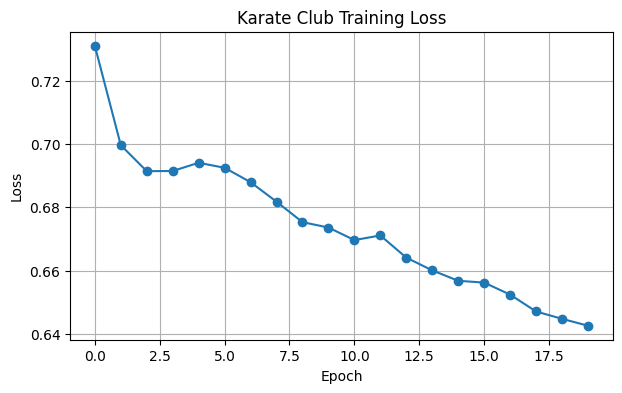

In [12]:
plt.figure(figsize=(7, 4))

plt.plot(losses, marker="o")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Karate Club Training Loss")

plt.grid()
plt.show()

In [13]:
model.eval()

start_time = time.time()

with torch.no_grad():

    predictions = model(X, A)

    predicted_labels = predictions[test_idx].argmax(dim=1)

karate_inference_time = time.time() - start_time

actual = y[test_idx].numpy()
predicted = predicted_labels.numpy()

karate_accuracy = accuracy_score(actual, predicted)

karate_balanced = balanced_accuracy_score(
    actual, predicted
)

karate_f1 = f1_score(
    actual, predicted,
    average="macro",
    zero_division=0
)

print("Accuracy:", karate_accuracy)
print("Balanced Accuracy:", karate_balanced)
print("Node Macro-F1:", karate_f1)

print(classification_report(
    actual,
    predicted,
    zero_division=0
))

Accuracy: 0.6363636363636364
Balanced Accuracy: 0.6666666666666666
Node Macro-F1: 0.6071428571428572
              precision    recall  f1-score   support

           0       1.00      0.33      0.50         6
           1       0.56      1.00      0.71         5

    accuracy                           0.64        11
   macro avg       0.78      0.67      0.61        11
weighted avg       0.80      0.64      0.60        11



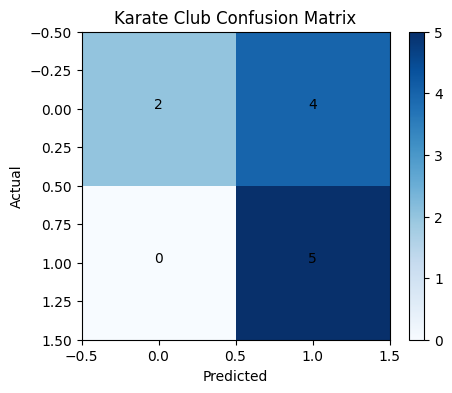

In [14]:
cm = confusion_matrix(actual, predicted)

plt.figure(figsize=(5, 4))

plt.imshow(cm, cmap="Blues")

plt.title("Karate Club Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.colorbar()

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j, i, cm[i, j], ha="center")

plt.show()

In [15]:
def generate_sbm_graphs(number=60):

    graphs = []
    labels = []

    for i in range(number):

        if i % 2 == 0:

            probabilities = [
                [0.40, 0.04],
                [0.04, 0.40]
            ]

            label = 0

        else:

            probabilities = [
                [0.16, 0.10],
                [0.10, 0.16]
            ]

            label = 1

        G = nx.stochastic_block_model(
            [8, 8],
            probabilities,
            seed=100 + i
        )

        graphs.append(G)
        labels.append(label)

    return graphs, torch.tensor(labels)


sbm_graphs, sbm_labels = generate_sbm_graphs()

print("Total graphs:", len(sbm_graphs))
print("Graph class counts:", torch.bincount(sbm_labels))

Total graphs: 60
Graph class counts: tensor([30, 30])


In [16]:
sbm_data = []

for G in sbm_graphs:

    features = extract_features(G)

    adjacency = adjacency_matrix(G)

    sbm_data.append((features, adjacency))

graph_indices = np.arange(len(sbm_graphs))

sbm_train_idx, sbm_test_idx = train_test_split(
    graph_indices,
    test_size=0.25,
    random_state=42,
    stratify=sbm_labels.numpy()
)

print("Training graphs:", len(sbm_train_idx))
print("Held-out graphs:", len(sbm_test_idx))

Training graphs: 45
Held-out graphs: 15


In [17]:
sbm_quantum = qml.qnn.TorchLayer(
    quantum_circuit,
    {"weights": (2,)}
)

sbm_classifier = nn.Linear(9, 2)

sbm_optimizer = torch.optim.Adam(
    list(model.parameters()) +
    list(sbm_quantum.parameters()) +
    list(sbm_classifier.parameters()),
    lr=LEARNING_RATE
)

sbm_losses = []

start_time = time.time()

for epoch in range(10):

    total_loss = 0

    model.train()

    for graph_id in sbm_train_idx:

        features, adjacency = sbm_data[graph_id]

        target = sbm_labels[graph_id].view(1)

        sbm_optimizer.zero_grad()

        h = model.classical_gnn(features, adjacency)

        graph_embedding = h.mean(dim=0)

        q_input = torch.tanh(graph_embedding[:2]) * np.pi

        q_output = sbm_quantum(q_input).reshape(1)

        combined = torch.cat([
            graph_embedding,
            q_output
        ]).reshape(1, 9)

        output = sbm_classifier(combined)

        loss = nn.CrossEntropyLoss()(output, target)

        loss.backward()

        sbm_optimizer.step()

        total_loss += loss.item()

    average_loss = total_loss / len(sbm_train_idx)

    sbm_losses.append(average_loss)

    print(
        "Epoch:",
        epoch + 1,
        "Loss:",
        round(average_loss, 4)
    )

sbm_train_time = time.time() - start_time

print("SBM training time:", round(sbm_train_time, 2), "seconds")

Epoch: 1 Loss: 0.6211
Epoch: 2 Loss: 0.3634
Epoch: 3 Loss: 0.2883
Epoch: 4 Loss: 0.3008
Epoch: 5 Loss: 0.288
Epoch: 6 Loss: 0.3218
Epoch: 7 Loss: 0.3262
Epoch: 8 Loss: 0.3545
Epoch: 9 Loss: 0.3434
Epoch: 10 Loss: 0.3352
SBM training time: 9.08 seconds


In [18]:
model.eval()
sbm_quantum.eval()
sbm_classifier.eval()

sbm_actual = []
sbm_predicted = []

start_time = time.time()

with torch.no_grad():

    for graph_id in sbm_test_idx:

        features, adjacency = sbm_data[graph_id]

        h = model.classical_gnn(features, adjacency)

        graph_embedding = h.mean(dim=0)

        q_input = torch.tanh(graph_embedding[:2]) * np.pi

        q_output = sbm_quantum(q_input).reshape(1)

        combined = torch.cat([
            graph_embedding,
            q_output
        ]).reshape(1, 9)

        output = sbm_classifier(combined)

        prediction = output.argmax(dim=1).item()

        sbm_predicted.append(prediction)

        sbm_actual.append(sbm_labels[graph_id].item())

sbm_inference_time = time.time() - start_time

sbm_accuracy = accuracy_score(sbm_actual, sbm_predicted)

sbm_balanced = balanced_accuracy_score(
    sbm_actual, sbm_predicted
)

sbm_f1 = f1_score(
    sbm_actual,
    sbm_predicted,
    average="macro",
    zero_division=0
)

print("SBM Accuracy:", sbm_accuracy)
print("SBM Balanced Accuracy:", sbm_balanced)
print("SBM Macro-F1:", sbm_f1)

print(classification_report(
    sbm_actual,
    sbm_predicted,
    zero_division=0
))

SBM Accuracy: 0.8
SBM Balanced Accuracy: 0.8125
SBM Macro-F1: 0.7963800904977376
              precision    recall  f1-score   support

           0       1.00      0.62      0.77         8
           1       0.70      1.00      0.82         7

    accuracy                           0.80        15
   macro avg       0.85      0.81      0.80        15
weighted avg       0.86      0.80      0.79        15



In [19]:
results = pd.DataFrame({

    "Experiment": [
        "Karate Club Node Classification",
        "SBM Held-out Graph Classification"
    ],

    "Accuracy": [
        karate_accuracy,
        sbm_accuracy
    ],

    "Balanced Accuracy": [
        karate_balanced,
        sbm_balanced
    ],

    "Macro-F1": [
        karate_f1,
        sbm_f1
    ],

    "Training Time (seconds)": [
        karate_train_time,
        sbm_train_time
    ],

    "Inference Time (seconds)": [
        karate_inference_time,
        sbm_inference_time
    ]
})

print("FINAL PERFORMANCE RESULTS")

display(results)

resource_cost = pd.DataFrame({
    "Quantum Resource": [
        "Qubits",
        "Circuit layers",
        "CNOT gates per circuit",
        "Shots per circuit"
    ],
    "Value": [
        N_QUBITS,
        1,
        1,
        SHOTS
    ]
})

print("QUANTUM RESOURCE COST")

display(resource_cost)

results.to_csv("graph_prediction_results.csv", index=False)

resource_cost.to_csv("quantum_resource_cost.csv", index=False)

print("Project completed successfully!")

FINAL PERFORMANCE RESULTS


,Experiment,Accuracy,Balanced Accuracy,Macro-F1,Training Time (seconds),Inference Time (seconds)
0,Karate Club Node Classification,0.636364,0.666667,0.607143,10.129775,0.645393
1,SBM Held-out Graph Classification,0.800000,0.812500,0.796380,9.081904,0.222388


QUANTUM RESOURCE COST


,Quantum Resource,Value
0,Qubits,2
1,Circuit layers,1
2,CNOT gates per circuit,1
3,Shots per circuit,100


Project completed successfully!


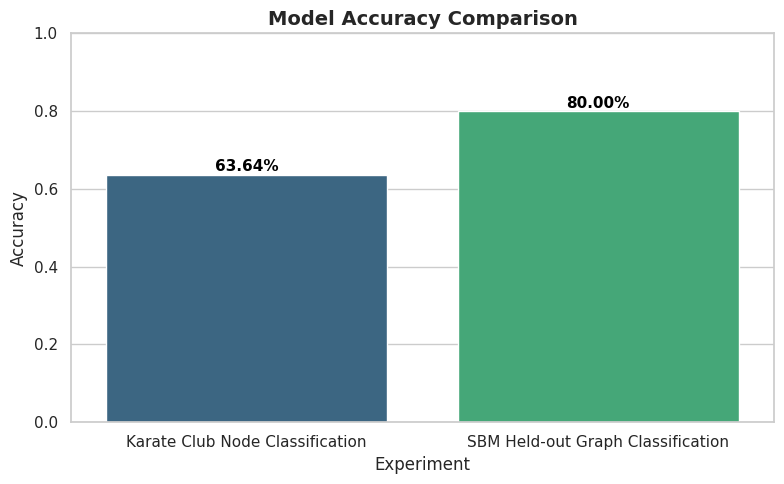

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set plot style
sns.set_theme(style="whitegrid")
plt.figure(figsize=(8, 5))

# Create bar plot
ax = sns.barplot(
    x="Experiment",
    y="Accuracy",
    data=results_df,
    palette="viridis",
    hue="Experiment",
    legend=False
)

# Customize chart
plt.title("Model Accuracy Comparison", fontsize=14, fontweight="bold")
plt.ylabel("Accuracy", fontsize=12)
plt.xlabel("Experiment", fontsize=12)
plt.ylim(0, 1.0)

# Add values on top of bars
for p in ax.patches:
    ax.annotate(
        f"{p.get_height():.2%}",
        (p.get_x() + p.get_width() / 2., p.get_height() + 0.02),
        ha='center',
        va='center',
        fontsize=11,
        color='black',
        fontweight='semibold'
    )

plt.tight_layout()
plt.show()

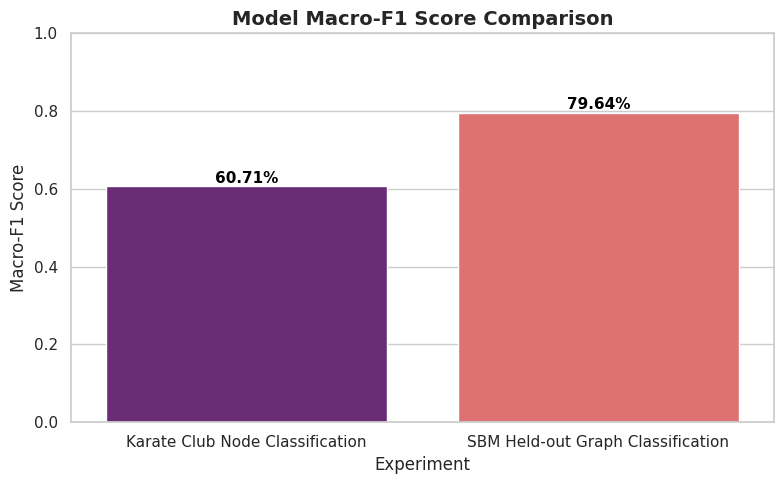

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set plot style
sns.set_theme(style="whitegrid")
plt.figure(figsize=(8, 5))

# Create bar plot for F1-score
ax = sns.barplot(
    x="Experiment",
    y="Macro-F1",
    data=results_df,
    palette="magma",
    hue="Experiment",
    legend=False
)

# Customize chart
plt.title("Model Macro-F1 Score Comparison", fontsize=14, fontweight="bold")
plt.ylabel("Macro-F1 Score", fontsize=12)
plt.xlabel("Experiment", fontsize=12)
plt.ylim(0, 1.0)

# Add values on top of bars
for p in ax.patches:
    ax.annotate(
        f"{p.get_height():.2%}",
        (p.get_x() + p.get_width() / 2., p.get_height() + 0.02),
        ha='center',
        va='center',
        fontsize=11,
        color='black',
        fontweight='semibold'
    )

plt.tight_layout()
plt.show()

In [23]:
# Format and display the results table nicely
styled_results = results_df.style.format({
    'Accuracy': '{:.2%}',
    'Balanced Accuracy': '{:.2%}',
    'Macro-F1': '{:.2%}',
    'Training Time (seconds)': '{:.2f}s',
    'Inference Time (seconds)': '{:.4f}s'
}).set_properties(**{
    'text-align': 'center',
    'font-size': '12pt'
}).set_table_styles([
    {'selector': 'th', 'props': [('background-color', '#4CAF50'), ('color', 'white'), ('font-weight', 'bold'), ('text-align', 'center')]}
])

display(styled_results)

,Experiment,Accuracy,Balanced Accuracy,Macro-F1,Training Time (seconds),Inference Time (seconds)
0,Karate Club Node Classification,63.64%,66.67%,60.71%,10.13s,0.6454s
1,SBM Held-out Graph Classification,80.00%,81.25%,79.64%,9.08s,0.2224s
